## ADA - Reddit Analysis - Part3

## Preliminary Hypothesis

Let's consider a sub-reddit B being attacked and B'a control sub-reddit, similar to B before the attack but that didn't receive the attack.

|  Q  |We expect : | What would change our mind |
| --- | --- | --- |
| Q1| Increased nb of links toward B in the following days / weeks | B/B' close to 1 |
|  Q2 |  A higher ratio of negative links compared to control | A non changing negative ratio |
|   Q3| A higher ratio of negative links comming from B | A non - changing or lower ratio of negative outcoming links |
| Q4 | A temporary effect | The activity and negativity excess remains increased after 6 months |



### 0 : Data Import

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
BLUE, RED, GREY = "#1E67B5", "#D02F2F", "#7F7F7F"   # same colors as chapter 2
DAY = pd.Timedelta(days=1)                    # handy unit for time arithmetic

In [2]:
# Load the two TSV files (hyperlinks in post bodies and in post titles) and stack them.
data_dir = Path("Data")
columns = ["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "POST_ID", "TIMESTAMP", "LINK_SENTIMENT"]

parts = []
for location in ["body", "title"]:
    part = pd.read_csv(data_dir / f"soc-redditHyperlinks-{location}.tsv", sep="\t", usecols=columns)
    part["LOCATION"] = location          # remember where the link was found
    parts.append(part)
links = pd.concat(parts, ignore_index=True)   # stack tables with the same columns

links["time"] = pd.to_datetime(links.pop("TIMESTAMP"))   # pop = take the column out, then convert it
links = links[links.SOURCE_SUBREDDIT != links.TARGET_SUBREDDIT]   # drop self-links

# Sort by time (ties broken by POST_ID/LOCATION so the order is deterministic).
# Sorting matters: "first negative link" and the fast time slicing below both rely on it.
links = links.sort_values(["time", "POST_ID", "LOCATION"]).reset_index(drop=True)

print(f"{len(links):,} links | {links.LINK_SENTIMENT.eq(-1).mean():.2%} negative")
print(links.time.min(), "->", links.time.max())

858,488 links | 9.58% negative
2013-12-31 16:20:20 -> 2017-04-30 16:58:21


### 1 - Events


#### 1.1 - Event Definition

In [13]:
MIN_LINKS = 5    # eligibility: at least 5 incoming links in the selection window

# For every subreddit, the time of the first negative link it ever received.
negatives = links[links.LINK_SENTIMENT == -1]
first_neg_time = negatives.groupby("TARGET_SUBREDDIT").time.min()

first_neg = negatives.drop_duplicates("TARGET_SUBREDDIT", keep="first")
events = first_neg.rename(columns={"SOURCE_SUBREDDIT": "A", "TARGET_SUBREDDIT": "B",
                                   "time": "t0", "LOCATION": "attack_location"})
events = events[["A", "B", "t0", "POST_ID", "attack_location"]]
n_attacked_ever = len(events)

# Keep only first attacks from 2015 onward (2014 is only used to check B was never attacked before).
events = events[events.t0 >= "2015-01-01"].reset_index(drop=True)
events["event_id"] = events.index


In order to facilitate the later processing (counting links before and after attack, computing the curves, negativity ratio and others), we create a tab that contains all the incoming links to B in the -180, +365 days window. 
- event_id : to which attack (therefore which B) do we refer to
- C : The community that sent the link
- rel_day : days since attack (- before, + after)
- is_neg : is the link negative 

In [21]:
def incoming_links(keys, links, lo=-180, hi=365):
    """One row per link received by key.B in [t0+lo, t0+hi) days, excluding links coming from A.
    `keys` needs the columns event_id, B, A, t0."""
    inc = links[["SOURCE_SUBREDDIT", "TARGET_SUBREDDIT", "time", "LINK_SENTIMENT"]].rename(
        columns={"SOURCE_SUBREDDIT": "C", "TARGET_SUBREDDIT": "B"})     # C = the third-party linker
    m = keys[["event_id", "B", "A", "t0"]].merge(inc, on="B")           # SQL-style join on the target B
    m["rel_day"] = (m["time"] - m["t0"]) / DAY                          # days relative to the attack
    m = m[(m.rel_day >= lo) & (m.rel_day < hi) & (m.C != m.A)]          # window, and never count A
    m["is_neg"] = m.LINK_SENTIMENT == -1
    return m[["event_id", "C", "rel_day", "is_neg"]].reset_index(drop=True)

long = incoming_links(events, links)
print(f"{len(long):,} incoming links around the attacks")

72,139 incoming links around the attacks


### 1.3 - Windows Definition

In [15]:
WINDOWS = {"elig": (-180, -90),   # used to select active subreddits
           "pre90": (-90, 0),     # baseline we measure on
           "pre30": (-30, 0)}

def add_counts(table, long, windows=WINDOWS):
    """Add, for each window, the number of incoming links (_n) and of negative ones (_neg)."""
    table = table.copy()
    for name, (lo, hi) in windows.items():
        w = long[(long.rel_day >= lo) & (long.rel_day < hi)]
        g = w.groupby("event_id").agg(**{f"{name}_n": ("C", "size"), f"{name}_neg": ("is_neg", "sum")})
        table = table.drop(columns=g.columns, errors="ignore").join(g, on="event_id")
    count_cols = [c for c in table if c.endswith(("_n", "_neg"))]
    table[count_cols] = table[count_cols].fillna(0).astype(int)   # no link at all means 0, not NaN
    return table

events = add_counts(events, long)
events["eligible"] = events.elig_n >= MIN_LINKS
events["horizon_ok"] = events.t0 <= links.time.max() - 365 * DAY    # 12 months of follow-up (Q4 only)

#### 1.3 - Visuals

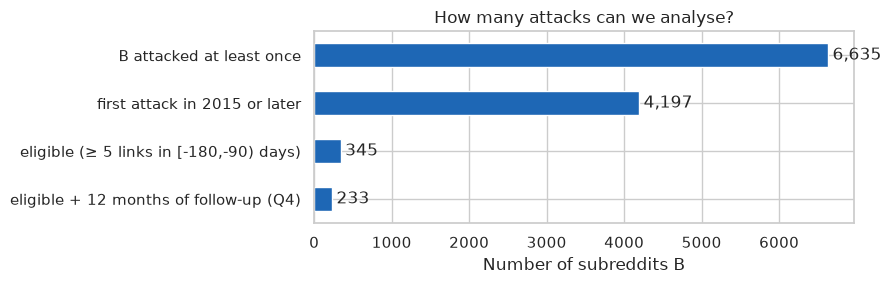

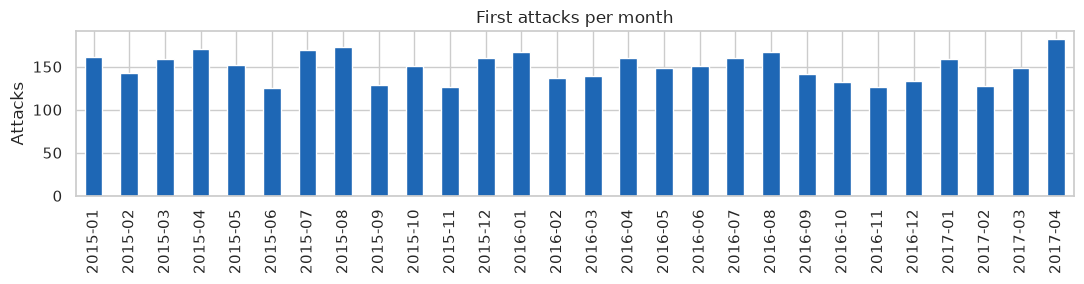

In [16]:
# Visual 1: the funnel, from all attacked subreddits down to the ones usable for each question.
funnel = pd.Series({
    "B attacked at least once": n_attacked_ever,
    "first attack in 2015 or later": len(events),
    f"eligible (≥ {MIN_LINKS} links in [-180,-90) days)": events.eligible.sum(),
    "eligible + 12 months of follow-up (Q4)": (events.eligible & events.horizon_ok).sum(),
})
ax = funnel[::-1].plot.barh(color=BLUE, figsize=(9, 3))   # [::-1] puts the first step on top
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
ax.set(title="How many attacks can we analyse?", xlabel="Number of subreddits B")
plt.tight_layout(); plt.show()

# Visual 2: number of first attacks per month, to spot shocks (e.g. June-July 2015).
monthly = events.t0.dt.to_period("M").value_counts().sort_index()
ax = monthly.plot(kind="bar", color=BLUE, figsize=(11, 3))
ax.set(title="First attacks per month", xlabel="", ylabel="Attacks")
plt.tight_layout(); plt.show()

## 2 - Controls

In [17]:
CALIPER = 0.5   # max allowed distance between B and its control (in log-count units)

link_times = links["time"].to_numpy()   # sorted array, lets us slice by date very fast

def find_control(ev):
    """Return (best control subreddit, distance) for one event, or None."""
    # Links of the 180 days before t0: binary search on the sorted time array instead of filtering 858k rows.
    start = np.searchsorted(link_times, (ev.t0 - 180 * DAY).to_datetime64())
    stop = np.searchsorted(link_times, ev.t0.to_datetime64())
    w = links.iloc[start:stop]
    w = w[w.SOURCE_SUBREDDIT != ev.A]                      # same rule as for B: ignore links from A

    # Count incoming links of every subreddit in the two windows (days before t0: >90 = elig, <=90 = pre90).
    period = np.where((ev.t0 - w.time) / DAY > 90, "elig", "pre90")
    counts = (w.assign(period=period).groupby(["TARGET_SUBREDDIT", "period"]).size()
                .unstack(fill_value=0).reindex(columns=["elig", "pre90"], fill_value=0))

    # Candidates: active enough, not B or A.
    cand = counts[counts.elig >= MIN_LINKS].drop(index=[ev.B, ev.A], errors="ignore")
    # "Never attacked yet": no negative link received before t0 + 1 day (this also removes same-day attacks).
    fn = first_neg_time.reindex(cand.index)
    cand = cand[(fn.isna() | (fn >= ev.t0 + DAY)).to_numpy()]
    if cand.empty:
        return None

    # Distance between B and each candidate: gap in the two counts, on a log scale
    # (log1p so that 100 vs 110 links counts as "close", while 5 vs 15 does not).
    dist = ((np.log1p(cand.elig) - np.log1p(ev.elig_n)).abs()
            + (np.log1p(cand.pre90) - np.log1p(ev.pre90_n)).abs())
    return dist.idxmin(), dist.min()

rows = []
for ev in events[events.eligible].itertuples():
    res = find_control(ev)
    if res is not None:
        rows.append({"event_id": ev.event_id, "control": res[0], "dist": res[1]})
controls = pd.DataFrame(rows)

n_elig = events.eligible.sum()
controls = controls[controls.dist <= CALIPER]              # drop bad matches rather than keep a poor control
print(f"{len(controls)} / {n_elig} events matched | {controls.control.nunique()} distinct controls")

339 / 345 events matched | 270 distinct controls


For 345 events, we found 339 controls. 270 uniques controls (indeed a group can serve as a control to different groups)

In [18]:
# Flag controls that get their first negative link within 30 days after t0.
# We keep them (dropping them would bias Q2 downward by construction) and check the effect later.
t0_by_event = events.set_index("event_id").t0
ctrl_t0 = t0_by_event.reindex(controls.event_id).reset_index(drop=True)
ctrl_first_neg = first_neg_time.reindex(controls.control).reset_index(drop=True)
controls["attacked_post30"] = (ctrl_first_neg < ctrl_t0 + 31 * DAY)    # NaT (never attacked) compares False
print(f"{controls.attacked_post30.mean():.1%} of controls are attacked within 30 days")

# Same incoming-links table and same counts as for the events: control.B plays the role of B.
ctrl_keys = controls.merge(events[["event_id", "A", "t0"]], on="event_id").rename(columns={"control": "B"})
ctrl_long = incoming_links(ctrl_keys, links)
controls = add_counts(controls.rename(columns={"control": "B"}), ctrl_long)
assert controls.elig_n.ge(MIN_LINKS).all()

3.6% of controls are attacked within 30 days


In [19]:
# Balance table: before the attack, B and its control should look alike.
first_seen = pd.concat([links.groupby("SOURCE_SUBREDDIT").time.min(),
                        links.groupby("TARGET_SUBREDDIT").time.min()]).groupby(level=0).min()
age = lambda B, t0: (t0 - first_seen.reindex(B).to_numpy()) / DAY      # days since first seen in the data (capped by 2014)

ev_m = events.set_index("event_id").loc[controls.event_id]
ct_m = controls.set_index("event_id")
ev_age = age(ev_m.B, ev_m.t0); ct_age = age(ct_m.B, ev_m.t0.to_numpy())
balance = pd.DataFrame({
    "B (attacked)": [ev_m.elig_n.mean(), ev_m.pre90_n.mean(), ev_m.pre30_n.mean(), ev_age.mean()],
    "B' (control)": [ct_m.elig_n.mean(), ct_m.pre90_n.mean(), ct_m.pre30_n.mean(), ct_age.mean()],
}, index=["links in [-180,-90)", "links in [-90,0)", "links in [-30,0)", "age in days (proxy)"])
display(balance.round(1))

,B (attacked),B' (control)
"links in [-180,-90)",9.3,9.3
"links in [-90,0)",8.3,8.4
"links in [-30,0)",3.0,2.8
age in days (proxy),569.0,492.7


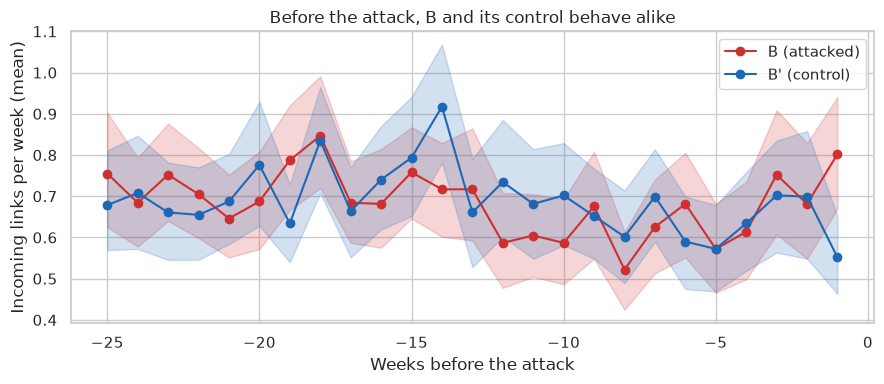

In [20]:
# Weekly number of incoming links per event, B vs control, in the 25 weeks before the attack.
def weekly_table(long, ids, weeks):
    w = long[long.event_id.isin(ids)].copy()
    w["week"] = np.floor(w.rel_day / 7).astype(int)                     # week -1 = days [-7, 0)
    tab = w.groupby(["event_id", "week"]).size().unstack(fill_value=0)
    return tab.reindex(index=ids, columns=weeks, fill_value=0)          # fill weeks with no link with 0

def bootstrap_mean(tab, n_boot=1000, seed=0):
    """Mean per week with a 95% interval, resampling EVENTS (rows) with replacement."""
    rng = np.random.default_rng(seed)
    X = tab.to_numpy()
    means = np.array([X[rng.integers(0, len(X), len(X))].mean(axis=0) for _ in range(n_boot)])
    low, high = np.percentile(means, [2.5, 97.5], axis=0)
    return X.mean(axis=0), low, high

ids, weeks = controls.event_id.to_numpy(), range(-25, 0)
fig, ax = plt.subplots(figsize=(9, 4))
for label, lg, color in [("B (attacked)", long, RED), ("B' (control)", ctrl_long, BLUE)]:
    mean, low, high = bootstrap_mean(weekly_table(lg, ids, weeks))
    ax.plot(list(weeks), mean, color=color, marker="o", label=label)
    ax.fill_between(list(weeks), low, high, color=color, alpha=0.2)
ax.set(title="Before the attack, B and its control behave alike", xlabel="Weeks before the attack",
       ylabel="Incoming links per week (mean)")
ax.legend(); plt.tight_layout(); plt.show()